In [8]:
import pickle
import matplotlib.pyplot as plt
import os
import numpy as np
import scipy as sp


## A series of functions to get the initial rates from the HMM transition matrix 

In [9]:
os.getcwd()

'/Users/jefferyzhou/Documents/johnson-lab/HMMS'

In [10]:
hmm = pickle.load(open("hb_hmm_fit_results.pkl", "rb"))

In [62]:
hmm

{'m': array([423.9135422 , 210.10793957,   2.749472  , 100.36434522,
         58.23094751,   2.36860914, 259.51818882, 106.177416  ,
          1.87377082]),
 'S': array([[ 5.92512451e+03,  3.89491741e+02, -5.62810553e+01,
          1.15740067e+03,  1.51978643e+02, -6.95337376e+01,
          1.89010454e+03,  1.34241619e+03, -3.48022422e+01],
        [ 3.89491741e+02,  1.43020736e+03,  1.35162286e+02,
          8.99049721e+00,  8.48779790e+01, -2.78310100e+01,
          2.95558721e+02,  5.37499697e+01, -6.64007612e+01],
        [-5.62810553e+01,  1.35162286e+02,  1.97301538e+02,
         -1.47620127e+01,  5.32614794e+01, -1.37590644e+01,
          7.86468825e+01, -3.17746753e+01,  2.92412522e+01],
        [ 1.15740067e+03,  8.99049721e+00, -1.47620127e+01,
          5.40969560e+02,  2.10335937e+02,  1.86936857e+01,
          6.77144790e+02,  3.49420327e+02,  3.49845467e+00],
        [ 1.51978643e+02,  8.48779790e+01,  5.32614794e+01,
          2.10335937e+02,  1.66934893e+02,  4.14732106

In [12]:
t_mat = hmm["transition_mat"]
t_mat.sum(axis=1)  # check that rows sum to 1

array([1., 1., 1., 1., 1., 1.])

In [ ]:
Q = 1/(0.05) * (t_mat - np.eye(t_mat.shape[0]))  # convert to rate matrix (this is /s rate); not the same as the on rate
Q[1, 2], Q[5, 4]

(np.float64(5.180775580456347), np.float64(2.8239942932720625))

In [13]:
def check_time_coupling(matrix):
    """
    If the sequence is fully time-decoupled, the joint factors into the product of the 
    marginals. We can check by seeing if all the rows of the transition matrix are the same.
    """
    return np.allclose(matrix, matrix[0])
    

In [14]:
check_time_coupling(t_mat)

False

Ergodicity of the Markov Transition Matrix

1. Aperiodicity -- trivially aperiodic, each state has a self return probability and GCD(1, ...) = 1
2. Irreducible -- it is possible to get from 1 state to any other state (can show with induction and transitivity of the communicativity)


A finite state Markov chain like the one we have here is guaranteed to have a stationary distribution


In [15]:
def get_mfpt_to_j(transition_matrix, j):
    r'''
    Find the mean first passage time from the equation 

    .. math::
    $m_{ij} = 1 + \sum_{k \neq j} P_{ik} m_{kj}$ for all i != j$


    '''
    n = transition_matrix.shape[0]
    idx = [i for i in range(n) if i != j]  # indices from 0 to n-1 excluding j
    Q = transition_matrix[np.ix_(idx, idx)]  # submatrix excluding j
    identity = np.eye(n - 1)  # identity matrix of size n-1 x n-1
    ones = np.ones(n - 1)  # vector of ones of size n-1
    m = np.linalg.solve(identity - Q, ones)  # solve (I - Q)m = 1 for m
    return m


def get_stationary_distribution(transition_matrix):
    """
    Find the stationary distribution of a Markov chain. The stationary distribution is the 
    normalized left eigenvector corresponding to the eigenvalue 1 of the transition matrix.
    Because we are working with a finite number of states, the stationary distribution exists and is unique.
    """
    eigenvalues, l_eigenvectors = sp.linalg.eig(
        transition_matrix, left=True, right=False
    )
    v = np.real(
        l_eigenvectors[:, 0]
    )  # get the real part of the left eigenvector corresponding to eigenvalue 1
    pi = v / np.sum(v)  # normalize to get stationary distribution

    return pi


def get_recurrence_time(pi, j):
    """
    The recurrence time for state j is the expected number of steps to return to state j,
    which is the inverse of the stationary probability of state j.
    """
    return 1 / pi[j]  # recurrence time is the inverse of the stationary probability


def build_mfpt_matrix(transition_matrix):
    """
    Build the full MFPT matrix for a Markov chain. The MFPT matrix is an n x n matrix where the entry (i, j) is the mean first passage time from state i to state j,
    and entry (i, i) is the recurrence time for state i.
    """
    n = transition_matrix.shape[0]
    mfpt_matrix = np.zeros((n, n))
    pi = get_stationary_distribution(transition_matrix)
    for j in range(n):
        r_j = get_recurrence_time(pi, j)
        # build row for the mfpt matrix
        mfpt_matrix_row = np.insert(get_mfpt_to_j(transition_matrix, j), j, r_j)
        mfpt_matrix[:, j] = mfpt_matrix_row
    return mfpt_matrix

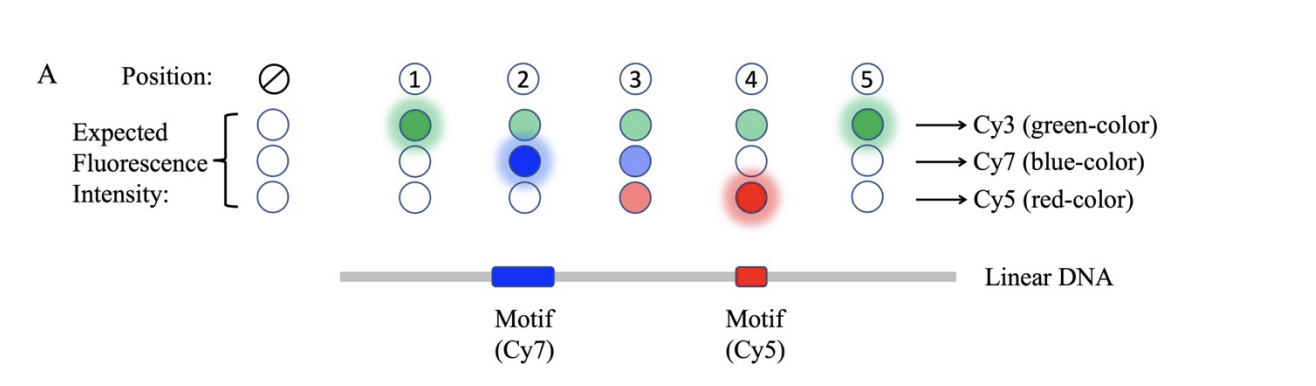

In [16]:
from IPython.display import display, Image
display(Image(filename="state_figure.png", width=600, height=400))

In [72]:
stationary = get_stationary_distribution(t_mat)
stationary

array([0.21972727, 0.04921948, 0.32355054, 0.2064456 , 0.1812016 ,
       0.0198555 ])

In [18]:
mfpt = build_mfpt_matrix(t_mat)
## these are all in units of 1/0.05 s; 50 ms per frame
mfpt = mfpt * 0.05  # convert to seconds
mfpt

array([[0.22755482, 2.57276511, 1.08715247, 0.96684864, 1.43320157,
        4.01282609],
       [2.87456294, 1.01585788, 0.28414426, 0.28772553, 0.80111655,
        4.49434723],
       [2.91736624, 1.84947646, 0.15453536, 0.2860718 , 0.75658358,
        4.48984246],
       [2.89006678, 1.90386797, 0.30883723, 0.24219455, 0.56737822,
        4.32562803],
       [2.91750175, 2.0714132 , 0.45690695, 0.21206113, 0.27593575,
        4.16688185],
       [1.61300353, 2.3439044 , 0.79603198, 0.59155473, 0.92652942,
        2.51819364]])

In [19]:
mfpt[1, 0], mfpt[3, 0], mfpt[5, 0]

(np.float64(2.874562944848405),
 np.float64(2.8900667770760053),
 np.float64(1.6130035330277295))

In [20]:
t_mat

array([[0.93104561, 0.00571584, 0.01565991, 0.0288345 , 0.00143397,
        0.01731018],
       [0.02246636, 0.49317929, 0.25903878, 0.22531557, 0.        ,
        0.        ],
       [0.01462955, 0.04243495, 0.70995874, 0.20176668, 0.03121008,
        0.        ],
       [0.01568722, 0.04824358, 0.34629521, 0.3162261 , 0.25754681,
        0.01600108],
       [0.00260801, 0.        , 0.03400202, 0.30364952, 0.63363394,
        0.02610651],
       [0.28208022, 0.        , 0.        , 0.17289795, 0.14119971,
        0.40382211]])

In [21]:
p_3to2 = t_mat[3, 2] # probability of transitioning from state 3 to state 2
p_3to4 = t_mat[3, 4] # probability of transitioning from state 3 to state 4

In [22]:
p_3to2_normalized = p_3to2 / (p_3to2 + p_3to4) # normalized probability of transitioning from state 3 to state 2
p_3to4_normalized = p_3to4 / (p_3to2 + p_3to4) # normalized probability of transitioning from state 3 to state 4
p_3to2_normalized, p_3to4_normalized

(np.float64(0.5734864359544558), np.float64(0.4265135640455442))

In [23]:
mfpt_3to2 = mfpt[3, 2]
mfpt_3to4 = mfpt[3, 4]

weighted_mfpt = p_3to2_normalized * mfpt_3to2 + p_3to4_normalized * mfpt_3to4
weighted_mfpt

np.float64(0.4191084674968585)

In [24]:
mfpt_3to2, mfpt_3to4, weighted_mfpt

(np.float64(0.3088372265759149),
 np.float64(0.5673782208528719),
 np.float64(0.4191084674968585))

In [25]:
mfpt_1to2 = mfpt[1, 2]
mfpt_5to4 = mfpt[5, 4]
mfpt_1to2, mfpt_5to4

## cy5(state 5) site is about half as many motifs as cy7 (state 2) site for hsp70 construct -- MFPT for 1 is much smaller than MFPT for 5

(np.float64(0.2841442587058622), np.float64(0.9265294160672641))

In [26]:
def radiative_reflexive_BC_rate(mfpt, D, R):

    r"""
    Calculate the microscopic association rate constant for a site with one radiative BC and one reflexive BC.

    We can solve for the rate constant k given the diffusion coefficient D, the reaction radius R, and the mean first passage time mfpt by solving:

    :math:
    \tau = \frac{R^2}{3D} + \frac{R}{k} 
    """

    k = (3*D*R) / (3*D*mfpt - R**2) ## solve for k
    return k

In [27]:
def estimate_B_form_DNA_length(sequence):
    """
    Estimate the length of B-form DNA in base pairs given a nucleotide sequence.
    B-form DNA has a rise of 0.34 nm per base pair. 


    Length of B-form DNA per base pair from basically any literature:
    Waters JT, Lu XJ, Galindo-Murillo R, Gumbart JC, Kim HD, Cheatham TE 3rd, Harvey SC. Transitions of Double-Stranded DNA Between the A- and B-Forms. J Phys Chem B. 2016 Aug 25;120(33):8449-56. doi: 10.1021/acs.jpcb.6b02155. Epub 2016 May 11. PMID: 27135262; PMCID: PMC5267635.
    """
    length_bp = len(sequence.strip())
    length_nm = length_bp * 0.34  # in nm
    return length_nm

In [28]:
def radiative_radiative_mftp(D, R, k1, k2):
    r"""
    Calculate the mean first passage time for a site with two radiative BCs.

    We can solve for the mean first passage time mfpt given the diffusion coefficient D, the reaction radius R, and the rate constants k1 and k2 by solving:

    :math:
    \tau = \frac{A}{2Dk_1} (k_1 R + 2D) - \frac{R^2}{6D}
    where 
    A = \frac{R(\frac{1}{k_2} - \frac{R}{2D})}{\frac{1}{k_2} - \frac{1}{k_1} - \frac{R}{D}}


    We would like tau to match the weighted mean first passage time calculated from the transition matrix given the k1, k2 we solve from 
    the radiative_reflexive_BC_rate function. This is a small validation that our model is at least self-consistent with the same theory.
    """
    A = R*(1/k2 - R/(2*D))/(1/k2 - 1/k1 - R/D)
    tau = A/(2*D*k1)*(k1*R + 2*D) - R**2/(6*D)
    return tau

In [29]:
total_R = estimate_B_form_DNA_length("TCATTTGTTTGGCAGAAAGAAAACTCTCAAAATTTCGTTGGCCGTTATAGCATATTCGTTTTGTGAGAGAGGGAGAGAGTACTATTGTTAACCCACAAGGTCGCACAGTAAACGGCACACTGTACGTGTTGCTTCGAGAGAGCGCGCcacctggtgtcgcgaaaagagcgccggagtataaatagag")
total_R # in nm

63.580000000000005

In [30]:
site_1 = "TCATTTGTTTGGCAGAAAGAAAACTCTCAAAATTTCGTTGGCCGTTATAGCATATTCGTTTTGTGA"
site_3 = "GTACTATTGTTAACCCACAAGGTCGCACAGTAAACGGCACACTGTACGTGTTGCTTC"
site_5 = "CGCGCcacctggtgtcgcgaaaagagcgccggagtataaatagag"

site_1_R = estimate_B_form_DNA_length(site_1)
site_3_R = estimate_B_form_DNA_length(site_3)
site_5_R = estimate_B_form_DNA_length(site_5)

site_1_R, site_3_R, site_5_R

(22.44, 19.380000000000003, 15.3)

In [ ]:
rate_1to2 = radiative_reflexive_BC_rate(mfpt_1to2, 0.15, site_1_R*1e-3) # D in um^2/s, R in um
rate_5to4 = radiative_reflexive_BC_rate(mfpt_5to4, 0.15, site_5_R*1e-3) # D in um^2/s, R in um
rate_1to2, rate_5to4 ## um/s

rate_1to2*1e3/1e6, rate_5to4*1e3/1e6 ## nm/us for nerdss

(np.float64(7.92862118981782e-05), np.float64(1.652251374449456e-05))

In [ ]:
mftp_3 = radiative_radiative_mftp(0.15, site_3_R*1e-3, rate_1to2, rate_5to4) # D in um^2/s, R in um
mftp_3 ## ~25%, or 0.109s off of the weighted MFPT from the transition matrix, which is 0.419s

np.float64(0.31044846261728576)

In [33]:
## get the survival distribution from state assignment
decodes = hmm["decodes"]
states_per_traj = [decode[0] for decode in decodes]

In [ ]:
### track contiguous runs of a single state to get dwell-time / survival distributions
def get_dwell_times(states_per_traj, n_states=None, drop_censored=True):
    """
    Collect the lengths (in frames) of every contiguous run of a single state across all trajectories.

    Parameters
    ----------
    states_per_traj : list of 1D arrays
        One state sequence per trajectory (e.g. Viterbi decodes).
    n_states : int, optional
        Number of states. Inferred from the data if not given.
    drop_censored : bool
        The first run in a trajectory is left-censored (we don't know when it started) and the
        last run is right-censored (we don't know when it ended). Both are biased short, so by
        default they are excluded. Set False to keep them (e.g. for a Kaplan-Meier style estimate).

    Returns
    -------
    dwells : dict {state: np.ndarray of run lengths}
    """
    if n_states is None:
        n_states = int(max(np.max(t) for t in states_per_traj)) + 1
    dwells = {s: [] for s in range(n_states)}

    for traj in states_per_traj:
        traj = np.asarray(traj).astype(int)
        if traj.size == 0:
            continue
        # indices where the state changes; run boundaries are [0, *change_idx, len]

        ## np.diff finds indices where the state changes
        change_idx = np.flatnonzero(np.diff(traj)) + 1

        ## imagine starts and ends like this:
        ## 1 5 9 10 15 25  first index and changepoints
        ## 5 9 10 15 25 32 changepoints up to the end of the trajectory
        starts = np.concatenate(([0], change_idx))
        ends = np.concatenate((change_idx, [traj.size]))
        lengths = ends - starts
        run_states = traj[starts]

        if drop_censored:
            # first and last runs touch the trajectory edges
            keep = slice(1, -1)
            lengths, run_states = lengths[keep], run_states[keep]

        for s, L in zip(run_states, lengths):
            dwells[s].append(L)

    return {s: np.asarray(v) for s, v in dwells.items()}


def survival_curve(dwell_lengths, dt=1.0):
    """
    Empirical survival function S(t) = P(dwell > t) from a set of dwell lengths.

    Returns (t, S) where t is in units of dt (e.g. seconds if dt is the frame time).

    This should fit a poisson distribution if the underlying process is a first-order reaction, in which case S(t) = exp(-k_off * t).
    (probability that we see 0 events in time t given a rate k_off)
    """
    dwell_lengths = np.asarray(dwell_lengths)
    t = np.arange(0, dwell_lengths.max() + 1) * dt
    S = np.array([(dwell_lengths * dt > ti).mean() for ti in t])
    return t, S


state 0: n=  13  mean=2.69 frames  theory=14.50
state 1: n= 113  mean=2.04 frames  theory=1.97
state 2: n= 422  mean=3.67 frames  theory=3.45
state 3: n= 622  mean=1.39 frames  theory=1.46
state 4: n= 295  mean=2.87 frames  theory=2.73
state 5: n=  45  mean=1.38 frames  theory=1.68


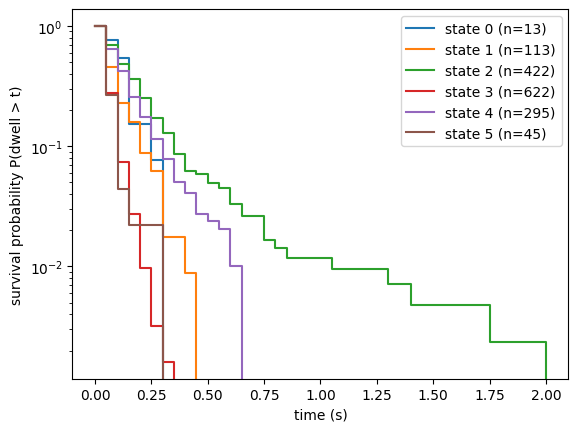

In [35]:
dt = 0.05  # s per frame
dwells = get_dwell_times(states_per_traj, n_states=t_mat.shape[0])

# sanity check: mean dwell in state i should be ~ 1/(1 - P_ii) frames
for s, d in dwells.items():
    print(f"state {s}: n={len(d):4d}  mean={d.mean() if len(d) else float('nan'):.2f} frames  theory={1/(1 - t_mat[s, s]):.2f}")

fig, ax = plt.subplots()
for s, d in dwells.items():
    if len(d) == 0:
        continue
    t, S = survival_curve(d, dt)
    ax.step(t, S, where="post", label=f"state {s} (n={len(d)})")
ax.set_xlabel("time (s)")
ax.set_ylabel("survival probability P(dwell > t)")
ax.set_yscale("log")
ax.legend()


In [36]:
# need to get survival probabilites of leaving a state to get the off rate estimates
def fit_poisson_to_survival_probability(time_points, survival_probabilities):
    def poisson_survival(t, k):
        return np.exp(-k * t)

    popt, pcov = sp.optimize.curve_fit(
        poisson_survival, time_points, survival_probabilities
    )
    return popt[0]

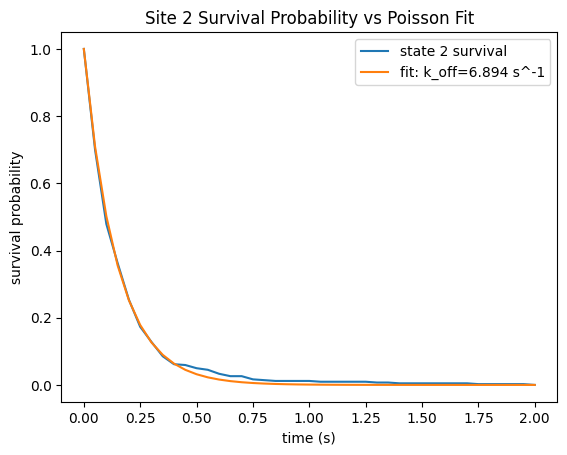

In [58]:
t, site2_survival = survival_curve(dwells[2], dt=dt)
site2_koff = fit_poisson_to_survival_probability(t, site2_survival)
site2_koff, t
plt.plot(t, site2_survival, label="state 2 survival")
plt.plot(t, np.exp(-site2_koff * t), label=f"fit: k_off={site2_koff:.3f} s^-1")
plt.title("Site 2 Survival Probability vs Poisson Fit")
plt.xlabel("time (s)")
plt.ylabel("survival probability")
plt.legend()

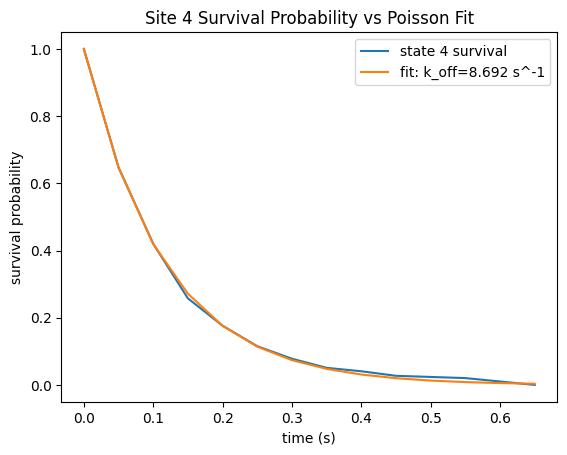

In [ ]:
t, site4_survival = survival_curve(dwells[4], dt=dt)
site4_koff = fit_poisson_to_survival_probability(t, site4_survival)
site4_koff
plt.plot(t, site4_survival, label="state 4 survival")
plt.plot(t, np.exp(-site4_koff * t), label=f"fit: k_off={site4_koff:.3f} s^-1")
plt.title("Site 4 Survival Probability vs Poisson Fit")
plt.xlabel("time (s)")
plt.ylabel("survival probability")
plt.legend()

The rates from the HMM, which have no information about the length of the different s1/s2 domains, are correlated with the lengths when we calculate MFTPs

In [ ]:
t, site1_survival = survival_curve(dwells[1], dt=dt)
site1_koff = fit_poisson_to_survival_probability(t, site1_survival)

t, site3_survival = survival_curve(dwells[3], dt=dt)
site3_koff = fit_poisson_to_survival_probability(t, site3_survival)

t, site5_survival = survival_curve(dwells[5], dt=dt)
site5_koff = fit_poisson_to_survival_probability(t, site5_survival)

site1_koff, site3_koff, site5_koff

(np.float64(14.144524479176047),
 np.float64(25.6020124346865),
 np.float64(27.098936528385845))

In [ ]:
p_site1 = stationary[1]
p_site3 = stationary[3]
p_site5 = stationary[5]

norm = p_site1 + p_site3 + p_site5

norm_p_site1 = p_site1 / norm
norm_p_site3 = p_site3 / norm
norm_p_site5 = p_site5 / norm

weighted_koff = p_site1 * norm_p_site1 * site1_koff + norm_p_site3 * site3_koff + norm_p_site5 * site5_koff
weighted_koff

np.float64(21.260668180476888)